# **Attention Res-Unet with Guided Decoder (ARU-GD)**
---

Here is the code implementation of the proposed model ***Attention Res-Unet with Guided Decoder (ARU-GD)*** as described in the paper **"Attention Res-UNet with Guided Decoder for Semantic Segmentation of Brain Tumors"**.

The automatic segmentation of brain tumors in Magnetic Resonance Imaging (MRI) plays a major role in accurate diagnosis and treatment planning. The present study proposes a new deep learning generator architecture called Attention Res-UNet with Guided Decoder (ARU-GD) for the segmentation of brain tumors. The proposed generator architecture have the capability to explicitly guide the learning process of each decoder layer. The individual loss function to each decoder layer helps to supervise the learning process of each layer in the decoder and thereby enables them to generate better feature maps. The attention gates in the generator focuses on the activations of relevant information instead of allowing all information to pass through the skip connections in the Res-UNet. Our model performed well in comparison to the baseline models i.e. UNet, Res-UNet, and Res-UNet with attention gates. The proposed ARU-GD also outperforms other popular deep learning models like VGG-Net, MobileNet, QuickNAT, DenseNet and XceptionNet. The proposed ARU-GD has achieved Dice Scores of 0.911, 0.876 and 0.801 and mean IoU of 0.838, 0.781 and 0.668 on the whole tumor, tumor core and enhancing tumor region respectively on unseen test data.







In [ ]:
import sys
print(sys.executable)


C:\Users\toumi\anaconda3\envs\tf210\python.exe


In [ ]:
pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install nibabel

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import kagglehub
import os
import nibabel as nib
import numpy as np

#path = kagglehub.dataset_download("aryashah2k/brain-tumor-segmentation-brats-2019")
#print("Dataset path:", path)

ModuleNotFoundError: No module named 'kagglehub'

In [ ]:
import os

print(os.listdir(path+"/MICCAI_BraTS_2019_Data_Training/HGG"))


['BraTS19_2013_10_1', 'BraTS19_2013_11_1', 'BraTS19_2013_12_1', 'BraTS19_2013_13_1', 'BraTS19_2013_14_1', 'BraTS19_2013_17_1', 'BraTS19_2013_18_1', 'BraTS19_2013_19_1', 'BraTS19_2013_20_1', 'BraTS19_2013_21_1', 'BraTS19_2013_22_1', 'BraTS19_2013_23_1', 'BraTS19_2013_25_1', 'BraTS19_2013_26_1', 'BraTS19_2013_27_1', 'BraTS19_2013_2_1', 'BraTS19_2013_3_1', 'BraTS19_2013_4_1', 'BraTS19_2013_5_1', 'BraTS19_2013_7_1', 'BraTS19_CBICA_AAB_1', 'BraTS19_CBICA_AAG_1', 'BraTS19_CBICA_AAL_1', 'BraTS19_CBICA_AAP_1', 'BraTS19_CBICA_ABB_1', 'BraTS19_CBICA_ABE_1', 'BraTS19_CBICA_ABM_1', 'BraTS19_CBICA_ABN_1', 'BraTS19_CBICA_ABO_1', 'BraTS19_CBICA_ABY_1', 'BraTS19_CBICA_ALN_1', 'BraTS19_CBICA_ALU_1', 'BraTS19_CBICA_ALX_1', 'BraTS19_CBICA_AME_1', 'BraTS19_CBICA_AMH_1', 'BraTS19_CBICA_ANG_1', 'BraTS19_CBICA_ANI_1', 'BraTS19_CBICA_ANP_1', 'BraTS19_CBICA_ANV_1', 'BraTS19_CBICA_ANZ_1', 'BraTS19_CBICA_AOC_1', 'BraTS19_CBICA_AOD_1', 'BraTS19_CBICA_AOH_1', 'BraTS19_CBICA_AOO_1', 'BraTS19_CBICA_AOP_1', 'BraTS19_

In [ ]:
import sys
print(sys.version)


3.10.19 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 16:41:31) [MSC v.1929 64 bit (AMD64)]


In [ ]:
import os
import sys

# Set cuDNN path
cudnn_path = r"C:\Users\clouduser\.conda\envs\tf_gpu\Lib\site-packages\nvidia\cudnn\bin"

# Add to system PATH
if cudnn_path not in os.environ['PATH']:
    os.environ['PATH'] = cudnn_path + os.pathsep + os.environ['PATH']

# Add to DLL search path (Windows-specific)
if hasattr(os, 'add_dll_directory'):
    os.add_dll_directory(cudnn_path)

print("cuDNN path added to environment")
print("Restart kernel after running this cell")

cuDNN path added to environment
Restart kernel after running this cell


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

# Test GPU computation
if tf.config.list_physical_devices('GPU'):
    print("\n✅ GPU is available!")
    with tf.device('/GPU:0'):
        a = tf.random.normal([1000, 1000])
        b = tf.random.normal([1000, 1000])
        c = tf.matmul(a, b)
        print("GPU computation successful!")
        print(f"Result shape: {c.shape}")
else:
    print("\n❌ No GPU detected")

TensorFlow version: 2.10.0
GPU devices: []

❌ No GPU detected


In [ ]:
import tensorflow as tf
print(tf.__version__)
print(tf.test.is_built_with_cuda())


2.10.0
True


In [ ]:
pip install matplotlib


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.1-py3-none-any.whl.metadata (5.6 kB)
   ---------------------------------------- 0.0/7.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/7.8 MB 2.8 MB/s eta 0:00:03
   ---- ----------------------------------- 0.8/7.8 MB 2.6 MB/s eta 0:00:03
   -------- ------------------------------- 1.6/7.8 MB 2.7 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/7.8 MB 2.9 MB/s eta 0:00:02
   -------------- ------------------------- 2.9/7.8 MB 2.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.4/7.8 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 4.2/7.8 MB 3.0 MB/s eta 0:00:02
   ------------------------ --------------- 4.7/7.8 MB 3.0 MB/s eta 0:00:02
   ---------------------------- ----------- 5.5/7.8 MB 3.1 MB/s eta 0:00:01
   -------------------------------- ------- 6.3/7.8 MB 3.1 MB/s eta 0:00:01
   ---------------------------------- ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import pickle

import keras
from keras.layers import Conv2D, Activation, Input, Dropout, Reshape, MaxPooling2D, UpSampling2D, Conv2DTranspose, Concatenate, multiply, Add, LeakyReLU
from keras.layers import BatchNormalization
from keras.models import Model
from keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
from keras.utils import *
from keras import regularizers
from keras import backend as K
from keras.models import load_model
from keras.layers import Lambda

In [ ]:
pip install SimpleITK

   ---------------------------------------- 0.0/18.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.8 MB ? eta -:--:--Note: you may need to restart the kernel to use updated packages.

   - -------------------------------------- 0.5/18.8 MB 1.9 MB/s eta 0:00:10
   - -------------------------------------- 0.8/18.8 MB 1.9 MB/s eta 0:00:10
   -- ------------------------------------- 1.3/18.8 MB 2.1 MB/s eta 0:00:09
   --- ------------------------------------ 1.8/18.8 MB 2.3 MB/s eta 0:00:08
   ----- ---------------------------------- 2.4/18.8 MB 2.4 MB/s eta 0:00:07
   ------ --------------------------------- 3.1/18.8 MB 2.5 MB/s eta 0:00:07
   ------- -------------------------------- 3.7/18.8 MB 2.5 MB/s eta 0:00:07
   -------- ------------------------------- 4.2/18.8 MB 2.5 MB/s eta 0:00:06
   ---------- ----------------------------- 5.0/18.8 MB 2.6 MB/s eta 0:00:06
   ----------- ---------------------------- 5.5/18.8 MB 2.7 MB/s eta 0:00:05
   ------------- -------

In [ ]:
import SimpleITK as sitk

# Data Preprocessing and creating Pickle files
You only need to run these sections once for creating the pickle files after data preprocessing, so that next time loading data is much faster and it takes up less storage, and we don't have to perform the data preprocessing steps again.

All the flair images of each patient have been put in one folder called "flair", and same has been done for T1, T1ce and T2 images.

The ground truths of each patient has been put in the folder called "seg".

These folders (flair, t1, t1ce, t2 and seg) are placed inside the **HGG** folder.

The pickle files are being saved inside the folder called "Colab Notebooks" where the program files are present.

In [ ]:
import glob
import os
path="C:/Users/clouduser/.cache/kagglehub/datasets/aryashah2k/brain-tumor-segmentation-brats-2019/versions/1"
hgg_folder = path + "/MICCAI_BraTS_2019_Data_Training/HGG/*"
patient_folders = glob.glob(hgg_folder)

flair_path = [os.path.join(p, os.path.basename(p) + "_flair.nii") for p in patient_folders]
t1_path    = [os.path.join(p, os.path.basename(p) + "_t1.nii") for p in patient_folders]
t1ce_path  = [os.path.join(p, os.path.basename(p) + "_t1ce.nii") for p in patient_folders]
t2_path   = [os.path.join(p, os.path.basename(p) + "_t2.nii") for p in patient_folders]
seg_path   = [os.path.join(p, os.path.basename(p) + "_seg.nii") for p in patient_folders]

print(len(flair_path))




259


In [ ]:
print(len(flair_path))

259


In [ ]:
X_flair=[]
for i in range(len(flair_path)):
   a = sitk.ReadImage(flair_path[i])
   a = sitk.GetArrayFromImage(a)
   for j in range(25):
       X_flair.append((a[50+2*j,:,:]))
print(np.shape(X_flair))

(6475, 240, 240)


In [ ]:
X_flair = np.asarray(X_flair).astype(np.float32)

In [ ]:
mean = X_flair.mean()
std = X_flair.std()
X_flair = (X_flair - mean)/(std + 1e-8)
np.min(X_flair), np.max(X_flair)

(-0.46841258, 16.260946)

In [ ]:
import pickle

pickle_out = open(r''C:/Users/clouduser/Desktop/YomnToumia/flair_25.pickle', 'wb')
pickle.dump(X_flair, pickle_out)
pickle_out.close()
del X_flair


In [ ]:
X_t1=[]
for i in range(len(t1_path)):
   a = sitk.ReadImage(t1_path[i])
   a = sitk.GetArrayFromImage(a)
   for j in range(25):
       X_t1.append((a[50+2*j,:,:]))
print(np.shape(X_t1))

(6475, 240, 240)


In [ ]:
X_t1 = np.asarray(X_t1).astype(np.float32)

In [ ]:
mean = X_t1.mean()
std = X_t1.std()
X_t1 = (X_t1 - mean)/(std + 1e-8)
np.min(X_t1), np.max(X_t1)

(-0.41608155, 24.9923)

In [ ]:
pickle_out = open(r''C:/Users/clouduser/Desktop/YomnToumia/t1_25.pickle', 'wb')
pickle.dump(X_t1, pickle_out)
pickle_out.close()
del X_t1

In [ ]:
X_t1ce=[]
for i in range(len(t1ce_path)):
    a = sitk.ReadImage(t1ce_path[i])
    a = sitk.GetArrayFromImage(a)
    for j in range(25):
        X_t1ce.append((a[50+2*j,:,:]))
print(np.shape(X_t1ce))

(6475, 240, 240)


In [ ]:
X_t1ce = np.asarray(X_t1ce).astype(np.float32)

In [ ]:
mean = X_t1ce.mean()
std = X_t1ce.std()
X_t1ce = (X_t1ce - mean)/(std + 1e-8)
np.min(X_t1ce), np.max(X_t1ce)

(-0.4047665, 31.285044)

In [ ]:
pickle_out = open(r''C:/Users/clouduser/Desktop/YomnToumia/t1ce_25.pickle', 'wb')
pickle.dump(X_t1ce, pickle_out)
pickle_out.close()
del X_t1ce

In [ ]:
X_t2=[]
for i in range(len(t2_path)):
    a = sitk.ReadImage(t2_path[i])
    a = sitk.GetArrayFromImage(a)
    for j in range(25):
        X_t2.append((a[50+2*j,:,:]))
print(np.shape(X_t2))

(6475, 240, 240)


In [ ]:
X_t2 = np.asarray(X_t2).astype(np.float32)

In [ ]:
mean = X_t2.mean()
std = X_t2.std()
X_t2 = (X_t2 - mean)/(std + 1e-8)
np.min(X_t2), np.max(X_t2)

(-0.42582026, 35.94511)

In [ ]:
pickle_out = open(r''C:/Users/clouduser/Desktop/YomnToumia/t2_25.pickle', 'wb')
pickle.dump(X_t2, pickle_out)
pickle_out.close()
del X_t2

In [ ]:
X_seg=[]
for i in range(len(seg_path)):
    a = sitk.ReadImage(seg_path[i])
    a = sitk.GetArrayFromImage(a)
    for j in range(25):
        X_seg.append((a[50+2*j,:,:]))
print(np.shape(X_seg))

(6475, 240, 240)


In [ ]:
X_seg = np.asarray(X_seg).astype(np.float32)

In [ ]:
pickle_out = open(r''C:/Users/clouduser/Desktop/YomnToumia/gt_25.pickle', 'wb')
pickle.dump(X_seg, pickle_out)
pickle_out.close()
del X_seg

# Loading Data from Pickle files

In this section, we load the data from the pickle files saved previously.

In [3]:
pickle_in = open(r'C:/Users/toumi/RESUnet/flair_25.pickle', 'rb')
X_flair = pickle.load(pickle_in)
pickle_in.close()

In [4]:
pickle_in = open(r'C:/Users/toumi/RESUnet/t1_25.pickle', 'rb')
X_t1 = pickle.load(pickle_in)
pickle_in.close()

In [5]:
pickle_in = open(r'C:/Users/toumi/RESUnet/t1ce_25.pickle', 'rb')
X_t1ce = pickle.load(pickle_in)
pickle_in.close()

In [6]:
pickle_in = open(r'C:/Users/toumi/RESUnet/t2_25.pickle', 'rb')
X_t2 = pickle.load(pickle_in)
pickle_in.close()

In [7]:
print(X_flair.shape[0])

6475


In [8]:
data = np.zeros((X_flair.shape[0],240,240,4))
for i in range(data.shape[0]):
    data[i,:,:,0] = X_flair[i,:,:]
    data[i,:,:,1] = X_t1[i,:,:]
    data[i,:,:,2] = X_t1ce[i,:,:]
    data[i,:,:,3] = X_t2[i,:,:]

In [9]:
print(np.shape(data))

(6475, 240, 240, 4)


In [10]:
del X_flair
del X_t1
del X_t2
del X_t1ce

In [39]:
pickle_in = open(r'C:/Users/toumi/RESUnet/gt_25.pickle', 'rb')
X_seg = pickle.load(pickle_in)
pickle_in.close()

In [40]:
print(np.unique(X_seg))

[0. 1. 2. 4.]


In [41]:
X_seg[X_seg == 4] = 3

In [42]:
print(np.unique(X_seg))

[0. 1. 2. 3.]


In [43]:
print(X_seg.shape)

(6475, 240, 240)


In [44]:
gt = to_categorical(X_seg, num_classes=None)
print(gt.shape)

(6475, 240, 240, 4)


In [45]:
print(data.shape)
print(gt.shape)

(6475, 240, 240, 4)
(6475, 240, 240, 4)


In [46]:
del X_seg

In [47]:
X_train = data[:4700]
X_valid = data[4700:5475]
X_test  = data[5475:]

In [48]:
print(X_train.shape)
print(X_valid.shape)
print(X_test.shape)

(4700, 240, 240, 4)
(775, 240, 240, 4)
(1000, 240, 240, 4)


In [49]:
Y_train = gt[:4700]
Y_valid = gt[4700:5475]
Y_test  = gt[5475:]

In [50]:
print(Y_train.shape)
print(Y_valid.shape)
print(Y_test.shape)

(4700, 240, 240, 4)
(775, 240, 240, 4)
(1000, 240, 240, 4)


# Data Augmentation

In [51]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [52]:
image_datagen = ImageDataGenerator(rotation_range=10,
                                    horizontal_flip=True,
                                    vertical_flip=True,
                                    width_shift_range=0.1,
                                    height_shift_range=0.1,
                                    shear_range=0.1,
                                    zoom_range=0.1)
mask_datagen = ImageDataGenerator(rotation_range=10,
                                    horizontal_flip=True,
                                    vertical_flip=True,
                                    width_shift_range=0.1,
                                    height_shift_range=0.1,
                                    shear_range=0.1,
                                    zoom_range=0.1)

In [53]:
seed = 1

In [54]:
image_generator = image_datagen.flow(X_train, batch_size=8, seed=seed)

mask_generator = mask_datagen.flow(Y_train, batch_size=8, seed=seed)

In [55]:
import tensorflow as tf

# ARU-GD model:

In [ ]:
batch_size = 8
image_size = 240
epochs = 100 #100

In [ ]:
from keras.layers import GlobalAveragePooling2D, Dense, Reshape, multiply

def squeeze_excitation_block(input_tensor, ratio=16):
    # Standard SE block to recalibrate channel-wise feature responses.
    init = input_tensor
    # Get the number of channels from the input tensor
    channel_axis = -1 if K.image_data_format() == "channels_last" else 1
    filters = init.shape[channel_axis]
    se_shape = (1, 1, filters)

    # Squeeze: Global Average Pooling
    se = GlobalAveragePooling2D()(init)
    se = Reshape(se_shape)(se)

    # Excitation: Two Dense layers (Bottleneck)
    se = Dense(filters // ratio, activation='relu', kernel_initializer='he_normal', use_bias=False)(se)
    se = Dense(filters, activation='sigmoid', kernel_initializer='he_normal', use_bias=False)(se)

    # Scale the original input
    x = multiply([init, se])
    return x

In [12]:
# Attention module block

def attention_block2d(x, g, inter_channel, i, data_format='channels_last'):

    theta_x = Conv2D(inter_channel, [2, 2], strides=[2, 2], data_format=data_format, kernel_regularizer=regularizers.l2(1e-5))(x)

    phi_g = Conv2D(inter_channel, [1, 1], strides=[1, 1],dilation_rate=i, data_format=data_format, kernel_regularizer=regularizers.l2(1e-5))(g)

    f = LeakyReLU(alpha=0.2)(Add()([theta_x, phi_g]))

    psi_f = Conv2D(1, [1, 1], strides=[1, 1],dilation_rate=i, data_format=data_format, kernel_regularizer=regularizers.l2(1e-5))(f)

    sigm_psi_f = Activation(activation='sigmoid')(psi_f)

    rate = UpSampling2D(size=[2, 2])(sigm_psi_f)

    att_x = multiply([x, rate])

    return att_x

In [13]:
def res_block(x, nb_filters, strides, i):

    res_path = BatchNormalization()(x)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    pool = MaxPooling2D(pool_size=(2, 2))(res_path)
    res_path = Conv2D(filters=nb_filters[0], kernel_size=(3, 3), padding='same',dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(pool)
    res_path = BatchNormalization()(res_path)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    res_path = Conv2D(filters=nb_filters[1], kernel_size=(3, 3), padding='same', dilation_rate=i,strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)

    shortcut = Conv2D(nb_filters[1], kernel_size=(1, 1),dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(pool)
    shortcut = BatchNormalization()(shortcut)

    res_path = Add()([shortcut, res_path])
    return res_path


In [14]:
#res block + SE
def res_block(x, nb_filters, strides, i):
    res_path = BatchNormalization()(x)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    pool = MaxPooling2D(pool_size=(2, 2))(res_path)

    # Convolutional layers as defined in the sources [3]
    res_path = Conv2D(filters=nb_filters[0], kernel_size=(3, 3), padding='same',dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(pool)
    res_path = BatchNormalization()(res_path)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    res_path = Conv2D(filters=nb_filters[1], kernel_size=(3, 3), padding='same', dilation_rate=i,strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)

    # --- ADD SE BLOCK HERE ---
    res_path = squeeze_excitation_block(res_path)

    shortcut = Conv2D(nb_filters[1], kernel_size=(1, 1), dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(pool)
    shortcut = BatchNormalization()(shortcut)

    res_path = Add()([shortcut, res_path])
    return res_path

In [15]:
def encoder(x):
    to_decoder = []

    main_path = Conv2D(filters=64, kernel_size=(3, 3), padding='same',dilation_rate=(1,1), strides=(1, 1), kernel_regularizer=regularizers.l2(1e-5))(x)
    main_path = BatchNormalization()(main_path)
    main_path = LeakyReLU(alpha=0.2)(main_path)

    main_path = Conv2D(filters=64, kernel_size=(3, 3), padding='same',dilation_rate=(1,1),strides=(1, 1), kernel_regularizer=regularizers.l2(1e-5))(main_path)

    shortcut = Conv2D(filters=64, kernel_size=(1, 1), strides=(1, 1),dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5))(x)
    shortcut = BatchNormalization()(shortcut)

    main_path = Add()([shortcut, main_path])

    # first branching to decoder
    to_decoder.append(main_path)

    main_path = res_block(main_path, [128, 128], [(2, 2), (1, 1)],(1,1))
    to_decoder.append(main_path)

    main_path = res_block(main_path, [256, 256], [(2, 2), (1, 1)],(2,2))
    to_decoder.append(main_path)

    main_path = res_block(main_path, [512, 512], [(2, 2), (1, 1)],(4,4))
    to_decoder.append(main_path)

    return to_decoder

In [16]:
def res_block_decoder(x, nb_filters, strides,i):

    res_path = BatchNormalization()(x)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    res_path = Conv2D(filters=nb_filters[0], kernel_size=(3, 3), padding='same', dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)
    res_path = BatchNormalization()(res_path)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    res_path = Conv2D(filters=nb_filters[1], kernel_size=(3, 3), padding='same', dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)

    shortcut = Conv2D(nb_filters[1], kernel_size=(1, 1), strides=strides[1], dilation_rate=i, kernel_regularizer=regularizers.l2(1e-5))(x)
    shortcut = BatchNormalization()(shortcut)

    res_path = Add()([shortcut, res_path])
    res_path = cbam_block(x)
    return res_path


In [17]:
 def channel_attention(x, ratio=16):
      channels = int(x.shape[-1])

      # Max pooling
      max_pool = GlobalAveragePooling2D()(x)
      max_pool = Dense(max(channels // ratio, 1), activation='relu')(max_pool)
      max_pool = Dense(channels, activation='sigmoid')(max_pool)

      # Avg pooling
      avg_pool = GlobalAveragePooling2D()(x)
      avg_pool = Dense(max(channels // ratio, 1), activation='relu')(avg_pool)
      avg_pool = Dense(channels, activation='sigmoid')(avg_pool)

      # Combine
      attention = Add()([max_pool, avg_pool])
      attention = Reshape((1, 1, channels))(attention)

      return Multiply()([x, attention])


def spatial_attention(x, kernel=7):
      # Max and avg pooling across channels
      max_pool = tf.reduce_max(x, axis=-1, keepdims=True)
      avg_pool = tf.reduce_mean(x, axis=-1, keepdims=True)

      # Concatenate
      concat = Concatenate()([max_pool, avg_pool])

      # Conv2D
      attention = Conv2D(1, (kernel, kernel), padding='same',
                        activation='sigmoid')(concat)

      return Multiply()([x, attention])


def cbam_block(x, ratio=16, kernel=7):
      # Channel attention first
      x = channel_attention(x, ratio)

      # Then spatial attention
      x = spatial_attention(x, kernel)

      return x


In [18]:
from keras.layers import Dense,GlobalAveragePooling2D,Concatenate,Multiply, Concatenate

In [19]:
#resblock decoder+se

def res_block_decoder(x, nb_filters, strides, i):
    res_path = BatchNormalization()(x)
    res_path = LeakyReLU(alpha=0.2)(res_path)

    # Use nb_filters[0] instead of nb_filters
    res_path = Conv2D(filters=nb_filters[0], kernel_size=(3, 3), padding='same', dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)
    res_path = BatchNormalization()(res_path)
    res_path = LeakyReLU(alpha=0.2)(res_path)
    # Use nb_filters[1] instead of nb_filters[3]
    res_path = Conv2D(filters=nb_filters[1], kernel_size=(3, 3), padding='same', dilation_rate=i, strides=strides[1], kernel_regularizer=regularizers.l2(1e-5))(res_path)

    # --- ADD SE BLOCK HERE ---
    res_path = squeeze_excitation_block(res_path)

    # Use nb_filters[1] instead of nb_filters[3]
    shortcut = Conv2D(nb_filters[1], kernel_size=(1, 1), strides=strides[1], dilation_rate=i, kernel_regularizer=regularizers.l2(1e-5))(x)
    shortcut = BatchNormalization()(shortcut)

    res_path = Add()([shortcut, res_path])
    res_path = cbam_block(x)
    return res_path

In [20]:
def decoder(x, from_encoder):

    # Layer 4
    attention_path1 = attention_block2d(from_encoder[3], x, 256, (1,1), data_format='channels_last')

    main_path1 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1),kernel_regularizer=regularizers.l2(1e-5))(x)
    main_path1 = Concatenate()([main_path1,attention_path1])
    main_path1 = res_block_decoder(main_path1, [512, 512], [(1, 1), (1, 1)],(4,4))

    hc1 = three_times_sample(main_path1)
    out_1 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='out_1')(hc1)


    # Layer 3
    attention_path2 = attention_block2d(from_encoder[2],main_path1 ,128,(1,1),data_format='channels_last')

    main_path2 = Conv2DTranspose(256, (2, 2), strides=(2, 2), dilation_rate=(1,1), padding='same', kernel_regularizer=regularizers.l2(1e-5))(main_path1)
    main_path2 = Concatenate()([main_path2,attention_path2])
    main_path2 = res_block_decoder(main_path2, [256, 256], [(1, 1), (1, 1)],(2,2))

    hc2 = two_times_sample(main_path2)
    out_2 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='out_2')(hc2)


    # Layer 2
    attention_path3 = attention_block2d(from_encoder[1],main_path2,64,(1,1),data_format='channels_last')

    main_path3 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5)) (main_path2)
    main_path3 = Concatenate()([main_path3,attention_path3])
    main_path3 = res_block_decoder(main_path3, [128, 128], [(1, 1), (1, 1)],(1,1))

    hc3 = one_time_sample(main_path3)
    out_3 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='out_3')(hc3)


    # Layer 1
    attention_path4 = attention_block2d(from_encoder[0],main_path3,32,(1,1),data_format='channels_last')

    main_path4 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1),kernel_regularizer=regularizers.l2(1e-5)) (main_path3)
    main_path4 = Concatenate()([main_path4,attention_path4])
    main_path4 = res_block_decoder(main_path4, [64, 64], [(1, 1), (1, 1)],(1,1))

    return main_path4, out_3, out_2, out_1

In [21]:
def three_times_sample(main_path):
    hyper1 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1),kernel_regularizer=regularizers.l2(1e-5)) (main_path)
    hyper2 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5)) (hyper1)
    hyper3 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5)) (hyper2)
    return hyper3


def two_times_sample(main_path):
    hyper1 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5))(main_path)
    hyper2 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1) ,kernel_regularizer=regularizers.l2(1e-5))(hyper1)
    return hyper2


def one_time_sample(main_path):
    hyper1 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same',dilation_rate=(1,1), kernel_regularizer=regularizers.l2(1e-5)) (main_path)
    return hyper1


In [22]:
def join_all_the_layers(hc1,hc2,hc3,hc4):

    combine1      =  Concatenate()([hc1,hc2])
    combine2      =  Concatenate()([hc3,hc4])
    combine_final =  Concatenate()([combine1,combine2])

    return combine_final


In [23]:
def aru_gd(input_shape):
    inputs = Input(shape=input_shape)

    to_decoder = encoder(inputs)

    path = res_block(to_decoder[3], [1024, 1024], [(2, 2), (1, 1)],(8,8))

    final_out, out_3, out_2, out_1 = decoder(path, from_encoder=to_decoder)

    # Use different names for the final Conv2D layers
    final_out = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='final_output')(final_out)
    out_3 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='output_3')(out_3)
    out_2 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='output_2')(out_2)
    out_1 = Conv2D(filters=4, kernel_size=(1, 1), activation='softmax', name='output_1')(out_1)

    return Model(inputs=inputs, outputs=[final_out, out_3, out_2, out_1])

# Loss Functions :




In [25]:
def dice_coef_0(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true[:, :, :, 0], [-1])
    y_pred_f = tf.reshape(y_pred[:, :, :, 0], [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_coef_1(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true[:, :, :, 1], [-1])
    y_pred_f = tf.reshape(y_pred[:, :, :, 1], [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_coef_2(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true[:, :, :, 2], [-1])
    y_pred_f = tf.reshape(y_pred[:, :, :, 2], [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_coef_3(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true[:, :, :, 3], [-1])
    y_pred_f = tf.reshape(y_pred[:, :, :, 3], [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


In [26]:
def dice_score(y_true, y_pred):
    d0 = dice_coef_0(y_true, y_pred,smooth=0.000001)
    d1 = dice_coef_1(y_true, y_pred,smooth=0.000001)
    d2 = dice_coef_2(y_true, y_pred,smooth=0.000001)
    d3 = dice_coef_3(y_true, y_pred,smooth=0.000001)

    dice_mean = (d0+d1+d2+d3)/4
    return dice_mean

def weighted_dice_score(y_true, y_pred):
    ds0 = dice_coef_0(y_true, y_pred,smooth=0.000001)
    ds1 = dice_coef_1(y_true, y_pred,smooth=0.000001)
    ds2 = dice_coef_2(y_true, y_pred,smooth=0.000001)
    ds3 = dice_coef_3(y_true, y_pred,smooth=0.000001)

    weighted_dice_mean = (ds0+(5*ds1)+(2*ds2)+(4*ds3))/12
    return weighted_dice_mean


In [27]:
def dice_loss(y_true, y_pred):
    return 1-dice_score(y_true, y_pred)


def weighted_dice_loss(y_true, y_pred):
    return 1-weighted_dice_score(y_true, y_pred)

In [28]:
def weighted_log_loss(y_true, y_pred):
    # scale predictions so that the class probas of each sample sum to 1
    y_pred /= tf.reduce_sum(y_pred, axis=-1, keepdims=True)
    # clip to prevent NaN's and Inf's
    y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1 - K.epsilon())
    # weights are assigned in this order : normal,necrotic,edema,enhancing
    weights=np.array([1,5,2,4],dtype=np.float32)
    weights = tf.constant(weights)
    loss = y_true * tf.math.log(y_pred) * weights
    loss = tf.reduce_mean(-tf.reduce_sum(loss, -1))
    return loss

In [29]:
def gen_dice_loss(y_true, y_pred):
    return weighted_dice_loss(y_true, y_pred)+weighted_log_loss(y_true,y_pred)

In [30]:
input_shape = (240,240,4)
losses = {
    'final_output':gen_dice_loss,
    'output_3':gen_dice_loss,
    'output_2':gen_dice_loss,
    'output_1':gen_dice_loss,
}
lossWeights = {"final_output": 0.5, "output_3": 0.125, "output_2": 0.125, "output_1": 0.125}
metrics = {
    'final_output': [dice_score],
    'output_3': [dice_score],
    'output_2': [dice_score],
    'output_1': [dice_score]
}

In [32]:
def focal_loss(alpha=0.25, gamma=2.0):
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        ce_loss = -y_true * tf.math.log(y_pred)
        focal_weight = (1 - y_pred) ** gamma
        focal_loss_val = alpha * focal_weight * ce_loss
        return tf.reduce_mean(tf.reduce_sum(focal_loss_val, axis=-1))
    return loss

def enhanced_combined_loss(y_true, y_pred):
    # Uses Source [5] weighted_dice_score and weighted_log_loss logic
    dice = 1 - weighted_dice_score(y_true, y_pred)
    ce = weighted_log_loss(y_true, y_pred)
    focal = focal_loss()(y_true, y_pred)
    return 0.5 * (dice + ce) + 0.3 * focal

# Training a new model :

If you want to train a new model using this architecture, then skip the cell containing **load_model** after this. Directly compile the model and train it.

In [ ]:
model = aru_gd(input_shape)

# Loading previously trained model :

After loading the previously trained model, compile it and then you can use it to generate predictions.

In [34]:
model1 = load_model('C:/Users/toumi/Downloads/Aru-gd_model1CBAM+focalloss.h5',compile=False)
model2 = load_model('C:/Users/toumi/Downloads/Aru-gd_model1CBAM.h5',compile=False)
model3 = load_model('C:/Users/toumi/Downloads/Aru-gd_model14.h5',compile=False)


# Compile :

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss=losses,
              loss_weights=lossWeights,
              metrics=metrics)

model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 240, 240, 4  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_63 (Conv2D)             (None, 240, 240, 64  2368        ['input_4[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_51 (BatchN  (None, 240, 240, 64  256        ['conv2d_63[0][0]']              
 ormalization)                  )                                                             

# Training the model :

In [ ]:
#earlystopping = EarlyStopping(monitor='val_loss', patience=20, verbose=0, mode='min')
from keras.callbacks import ModelCheckpoint

filepath = 'C:/Users/clouduser/Desktop/YomnToumia/ARUGD_training_checkpointCBAM.h5'

# Save model at every epoch
checkpoint = ModelCheckpoint(
    filepath,
    monitor='loss',
    verbose=1,
    save_best_only=False,
    save_freq='epoch',  # replaces `period=1`
    mode='min'
)


In [ ]:
print(model.outputs)


[<KerasTensor: shape=(None, 240, 240, 4) dtype=float32 (created by layer 'final_output')>, <KerasTensor: shape=(None, 240, 240, 4) dtype=float32 (created by layer 'output_3')>, <KerasTensor: shape=(None, 240, 240, 4) dtype=float32 (created by layer 'output_2')>, <KerasTensor: shape=(None, 240, 240, 4) dtype=float32 (created by layer 'output_1')>]


In [ ]:
#pip install scipy


In [ ]:
import scipy
print(scipy.__version__)


1.15.3


In [ ]:
def train_gen(image_generator, mask_generator):
    """Generator that yields (images, (mask, mask, mask, mask))"""
    while True:
        images = next(image_generator)  # (8, 240, 240, 4)
        masks = next(mask_generator)    # (8, 240, 240, 4)

        # Return the SAME mask for all 4 outputs
        # Each should be the full (8, 240, 240, 4)
        yield images, (masks, masks, masks, masks)

# Verify it works
test_gen = train_gen(image_generator, mask_generator)
test_images, test_masks = next(test_gen)
print(f"Images shape: {test_images.shape}")
print(f"Mask 1 shape: {test_masks[0].shape}")  # Should be (8, 240, 240, 4)
print(f"Mask 2 shape: {test_masks[1].shape}")  # Should be (8, 240, 240, 4)
print(f"Mask 3 shape: {test_masks[2].shape}")  # Should be (8, 240, 240, 4)
print(f"Mask 4 shape: {test_masks[3].shape}")  # Should be (8, 240, 240, 4)

Images shape: (8, 240, 240, 4)
Mask 1 shape: (8, 240, 240, 4)
Mask 2 shape: (8, 240, 240, 4)
Mask 3 shape: (8, 240, 240, 4)
Mask 4 shape: (8, 240, 240, 4)


In [ ]:
# Test if the dataset is actually producing data
print("Testing train_dataset...")
try:
    for images, masks in train_dataset.take(1):
        print(f"Images shape: {images.shape}")
        print(f"Masks type: {type(masks)}")
        if isinstance(masks, tuple):
            print(f"Number of mask outputs: {len(masks)}")
            for i, mask in enumerate(masks):
                print(f"  Mask {i+1} shape: {mask.shape}")
        break
except Exception as e:
    print(f"ERROR: {e}")
    print("\nDataset appears to be empty or malformed!")

Testing train_dataset...
ERROR: name 'train_dataset' is not defined

Dataset appears to be empty or malformed!


In [ ]:
# Check model output names and shapes
print("=== Model Output Information ===")
print(f"Number of outputs: {len(model.outputs)}")
for i, output in enumerate(model.outputs):
    print(f"Output {i+1}: {output.name}, shape: {output.shape}")



=== Model Output Information ===
Number of outputs: 4
Output 1: final_output/Softmax:0, shape: (None, 240, 240, 4)
Output 2: output_3/Softmax:0, shape: (None, 240, 240, 4)
Output 3: output_2/Softmax:0, shape: (None, 240, 240, 4)
Output 4: output_1/Softmax:0, shape: (None, 240, 240, 4)


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Create datasets
train_dataset = tf.data.Dataset.from_generator(
    lambda: train_gen(image_generator, mask_generator),
    output_signature=(
        tf.TensorSpec(shape=(None, 240, 240, 4), dtype=tf.float32),
        (
            tf.TensorSpec(shape=(None, 240, 240, 4), dtype=tf.float32),
            tf.TensorSpec(shape=(None, 240, 240, 4), dtype=tf.float32),
            tf.TensorSpec(shape=(None, 240, 240, 4), dtype=tf.float32),
            tf.TensorSpec(shape=(None, 240, 240, 4), dtype=tf.float32),
        )
    )
).prefetch(tf.data.AUTOTUNE)

valid_dataset = tf.data.Dataset.from_tensor_slices((
    X_valid.astype(np.float32),
    (
        Y_valid.astype(np.float32),
        Y_valid.astype(np.float32),
        Y_valid.astype(np.float32),
        Y_valid.astype(np.float32),
    )
)).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Calculate steps per epoch
steps_per_epoch = len(X_train) // batch_size
print(f"Training samples: {len(X_train)}")
print(f"Batch size: {batch_size}")
print(f"Steps per epoch: {steps_per_epoch}")

# Train the model
history = model.fit(
    train_dataset,
    validation_data=valid_dataset,
    steps_per_epoch=steps_per_epoch,
    epochs=epochs,
    callbacks=[checkpoint],
    verbose=1
)

Training samples: 4700
Batch size: 8
Steps per epoch: 587
Epoch 1/100
587/587 [==============================] - ETA: 0s - loss: 1.1812 - final_output_loss: 0.7681 - output_3_loss: 1.9870 - output_2_loss: 1.9283 - output_1_loss: 1.8407 - final_output_dice_score: 0.5258 - output_3_dice_score: 0.1504 - output_2_dice_score: 0.1548 - output_1_dice_score: 0.1684
Epoch 1: saving model to C:/Users/clouduser/Desktop/YomnToumia\ARUGD_training_checkpointCBAM.h5
587/587 [==============================] - 209s 319ms/step - loss: 1.1812 - final_output_loss: 0.7681 - output_3_loss: 1.9870 - output_2_loss: 1.9283 - output_1_loss: 1.8407 - final_output_dice_score: 0.5258 - output_3_dice_score: 0.1504 - output_2_dice_score: 0.1548 - output_1_dice_score: 0.1684 - val_loss: 1.2250 - val_final_output_loss: 0.9139 - val_output_3_loss: 1.9130 - val_output_2_loss: 1.8668 - val_output_1_loss: 1.7831 - val_final_output_dice_score: 0.4547 - val_output_3_dice_score: 0.1625 - val_output_2_dice_score: 0.1656 - val

In [ ]:
model.save('C:/Users/clouduser/Desktop/YomnToumia/Aru-gd_model1CBAM.h5', include_optimizer=True)

# Generating Predictions :

In [56]:
pred1 = model1.predict(X_test, batch_size=1)
pred2 = model2.predict(X_test, batch_size=1)
pred3 = model3.predict(X_test, batch_size=1)

1000/1000 [==============================] - 394s 393ms/step


TypeError: unsupported operand type(s) for /: 'list' and 'int'

In [57]:
pred1 = np.array(pred1)
pred2 = np.array(pred2)
pred3 = np.array(pred3)

# Average predictions (element-wise)
pred = (pred1 + pred2 + pred3) / 3

In [58]:
print(np.shape(pred))

(4, 1000, 240, 240, 4)


In [59]:
pred = np.argmax(pred, axis=-1)

In [60]:
#To choose the output from the final layer only, we take the slices in the 0th index.
predicted_images = np.reshape(pred[0,:,:,:], (1000,240,240))

In [61]:
GT = np.argmax(Y_test, axis=-1)
print(GT.shape)

(1000, 240, 240)


In [62]:
predicted_images[predicted_images==3] = 4
GT[GT==3] = 4

# Metrics :

In [63]:
def iou_coef(s,g):
    num = np.sum(np.multiply(s,g))
    denom=s.sum() + g.sum() - num
    if denom==0:
        return 1
    else:
        return num/denom

In [64]:
def iou_whole(pred, orig_label):
    #computes dice for the whole tumor
    return iou_coef(pred>0,orig_label>0)


def iou_en(pred, orig_label):
    #computes dice for enhancing region
    return iou_coef(pred==4,orig_label==4)


def iou_core(pred, orig_label):
    #computes dice for core region
    seg_=np.copy(pred)
    ground_=np.copy(orig_label)
    seg_[seg_==2]=0
    ground_[ground_==2]=0
    return iou_coef(seg_>0,ground_>0)

In [65]:
predicted_images = predicted_images.astype(np.int32)
GT = GT.astype(np.int32)

iou_complete  = iou_whole(predicted_images,GT)
iou_enhancing = iou_en(predicted_images,GT)
iou_core      = iou_core(predicted_images,GT)

print("iou complete tumor score : {:0.4f}".format(iou_complete))
print("iou core tumor score (tt sauf vert): {:0.4f}".format(iou_core))
print("iou enhancing tumor score (jaune):{:0.4f} ".format(iou_enhancing))

iou complete tumor score : 0.8418
iou core tumor score (tt sauf vert): 0.7594
iou enhancing tumor score (jaune):0.6646 


In [66]:
### METRICS

def binary_dice3d(s,g):
    #dice score of two 3D volumes
    num=np.sum(np.multiply(s, g))
    denom=s.sum() + g.sum()
    if denom==0:
        return 1
    else:
        return  2.0*num/denom



def DSC_whole(pred, orig_label):
    #computes dice for the whole tumor
    return binary_dice3d(pred>0,orig_label>0)


def DSC_en(pred, orig_label):
    #computes dice for enhancing region
    return binary_dice3d(pred==4,orig_label==4)


def DSC_core(pred, orig_label):
    #computes dice for core region
    seg_=np.copy(pred)
    ground_=np.copy(orig_label)
    seg_[seg_==2]=0
    ground_[ground_==2]=0
    return binary_dice3d(seg_>0,ground_>0)

In [67]:
Dice_complete=DSC_whole(predicted_images,GT)
Dice_enhancing=DSC_en(predicted_images,GT)
Dice_core=DSC_core(predicted_images,GT)

print("Dice complete tumor score : {:0.4f}".format(Dice_complete))
print("Dice core tumor score (tt sauf vert): {:0.4f}".format(Dice_core))
print("Dice enhancing tumor score (jaune):{:0.4f} ".format(Dice_enhancing))

Dice complete tumor score : 0.9141
Dice core tumor score (tt sauf vert): 0.8632
Dice enhancing tumor score (jaune):0.7985 


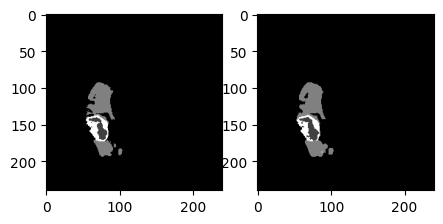

In [68]:
plt.figure(figsize=[5,5])
%matplotlib inline

plt.subplot(121)
curr_img = np.reshape(GT[350],(240,240))
plt.imshow(curr_img, cmap='gray')


plt.subplot(122)
curr_img = np.reshape(predicted_images[350], (240,240))
plt.imshow(curr_img, cmap='gray')